# 01 Data and preprocessing

**Purpose.** Inspect the prepared data used by the main experiments: a 50,000-flow stratified sample of the CICIoMT2024 WiFi/MQTT partition, 25 selected flow features, 16 PCA components, eight operational classes.

**Inputs.** `archive/prepared_data.npz`, `archive/scaler.joblib`, `archive/pca_multi.joblib`.

**Important note on preprocessing.** In the main experiments the constant and correlation filters, the ANOVA selector (25 of 35 features), the scaler and the PCA were fitted once on the 50,000-flow sample before splitting into training, validation and test partitions.
The split-protocol experiments (cluster notebook 16) re-fit every step inside each training partition. The paper discusses the consequence.

In [1]:
# --- setup: work from the laptop/ folder so that relative paths resolve ---
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
pd.set_option("display.precision", 4)
print("working folder:", ROOT)

working folder: <home>\Documents\Marwen_quintuimMachine\Quantium machine submission\journal_of_network_and_computer_applications\revision round 2\github_repo\QMedShield\laptop


In [2]:
d = np.load("archive/prepared_data.npz", allow_pickle=True)
print({k: d[k].shape for k in d.files})
CLASSES = ["Benign", "ARP Spoofing", "Reconnaissance", "MQTT Malformed", "MQTT DoS", "MQTT DDoS", "DoS", "DDoS"]
tab = pd.DataFrame({"train": np.bincount(d["y_train_m"], minlength=8),
                    "validation": np.bincount(d["y_val_m"], minlength=8),
                    "test": np.bincount(d["y_test_m"], minlength=8)}, index=CLASSES)
tab["test %"] = 100 * tab["test"] / tab["test"].sum()
tab

{'X_train_b': (35000, 16), 'X_val_b': (7500, 16), 'X_test_b': (7500, 16), 'y_train_b': (35000,), 'y_val_b': (7500,), 'y_test_b': (7500,), 'X_train_m': (35000, 16), 'X_val_m': (7500, 16), 'X_test_m': (7500, 16), 'y_train_m': (35000,), 'y_val_m': (7500,), 'y_test_m': (7500,), 'X_train_m_smote': (35000, 16), 'y_train_m_smote': (35000,), 'X_pca_b': (50000, 16), 'X_pca_m': (50000, 16), 'X_scaled': (50000, 25), 'y_binary': (50000,), 'y_multiclass': (50000,), 'class_weights_b': (2,), 'class_weights_m': (8,), 'kept_names': (25,)}


,train,validation,test,test %
Benign,967,207,208,2.7733
ARP Spoofing,70,15,15,0.2000
Reconnaissance,500,107,107,1.4267
MQTT Malformed,22,5,4,0.0533
MQTT DoS,284,61,61,0.8133
MQTT DDoS,962,206,206,2.7467
DoS,8805,1887,1887,25.1600
DDoS,23390,5012,5012,66.8267


In [3]:
import joblib
pca = joblib.load("archive/pca_multi.joblib")
print("PCA components:", pca.n_components_, " explained variance: %.1f%%" % (100 * pca.explained_variance_ratio_.sum()))
print("25 selected features:")
print([str(x) for x in d["kept_names"]])

PCA components: 16  explained variance: 96.3%
25 selected features:
['Header_Length', 'Duration', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'TCP', 'UDP', 'ARP', 'ICMP', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Variance']


<home>\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator PCA from version 1.6.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


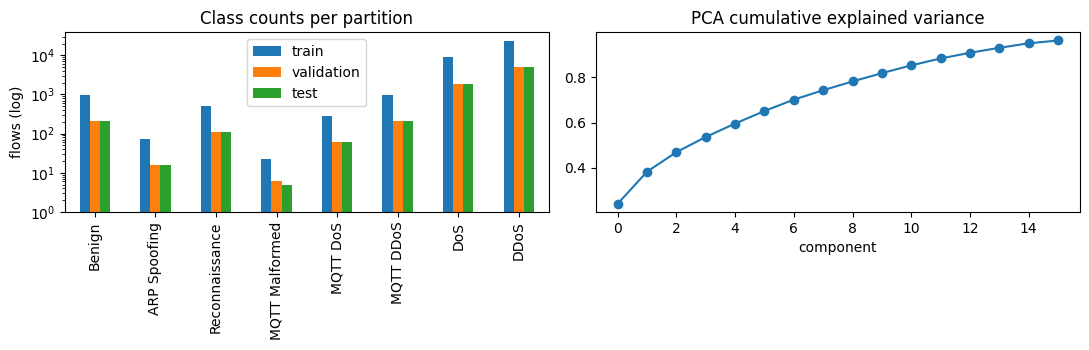

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
tab[["train", "validation", "test"]].plot.bar(ax=ax[0], log=True); ax[0].set_title("Class counts per partition"); ax[0].set_ylabel("flows (log)")
ax[1].plot(np.cumsum(pca.explained_variance_ratio_), marker="o"); ax[1].set_title("PCA cumulative explained variance"); ax[1].set_xlabel("component")
plt.tight_layout(); plt.show()